# Google Play Store Apps Analysis

## Project Overview

In this project, I explore the Google Play Store dataset using Python.

The main goal is to investigate app characteristics, distributions, ratings, genres, and installation patterns.

## Tools and Libraries
- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn

## Analysis Questions
- How many free and paid apps are available on the Google Play Store?
- Which genres contain the largest number of apps?
- What are the most common reported install thresholds?
- Is there a relationship between the number of installs and reviews?
- How are app ratings distributed?
- Is there a relationship between the number of installs and app ratings?
- Which genres have the highest sum of reported install thresholds?

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
data=pd.read_csv("googleplaystore.csv")
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 10841 entries, 0 to 10840
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   App             10841 non-null  str    
 1   Category        10841 non-null  str    
 2   Rating          9367 non-null   float64
 3   Reviews         10841 non-null  str    
 4   Size            10841 non-null  str    
 5   Installs        10841 non-null  str    
 6   Type            10840 non-null  str    
 7   Price           10841 non-null  str    
 8   Content Rating  10840 non-null  str    
 9   Genres          10841 non-null  str    
 10  Last Updated    10841 non-null  str    
 11  Current Ver     10833 non-null  str    
 12  Android Ver     10838 non-null  str    
dtypes: float64(1), str(12)
memory usage: 1.1 MB


In [3]:
data.columns

Index(['App', 'Category', 'Rating', 'Reviews', 'Size', 'Installs', 'Type',
       'Price', 'Content Rating', 'Genres', 'Last Updated', 'Current Ver',
       'Android Ver'],
      dtype='str')

In [4]:
data["Installs"].value_counts()

Installs
1,000,000+        1579
10,000,000+       1252
100,000+          1169
10,000+           1054
1,000+             907
5,000,000+         752
100+               719
500,000+           539
50,000+            479
5,000+             477
100,000,000+       409
10+                386
500+               330
50,000,000+        289
50+                205
5+                  82
500,000,000+        72
1+                  67
1,000,000,000+      58
0+                  14
0                    1
Free                 1
Name: count, dtype: int64

In [5]:
data[data["Installs"]=="Free"]
# اطلاعات این ردیف غلط وارد شده

,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
10472,Life Made WI-Fi Touchscreen Photo Frame,1.9,19.0,3.0M,"1,000+",Free,0,Everyone,NaN,"February 11, 2018",1.0.19,4.0 and up,NaN


In [6]:
data.shape

(10841, 13)

In [7]:
data=data[data["Installs"]!="Free"].copy()
# data=data.drop(data[data["Installs"]=="Free"].index)
data.shape

(10840, 13)

In [8]:
data["Reviews"]=pd.to_numeric(data["Reviews"])
data["Installs"] = (data["Installs"].str.replace(",", "", regex=False).str.replace("+", "", regex=False).astype(int))

data[["Reviews","Installs"]].dtypes

Reviews     int64
Installs    int64
dtype: object

In [9]:
data["Type"].value_counts()

Type
Free    10039
Paid      800
Name: count, dtype: int64

### Number of Free and Paid Apps
- This chart compares the number of free and paid apps available on the Google Play Store. It provides an overview of the distribution of apps based on their pricing type.

C:\Users\TS\AppData\Local\Temp\ipykernel_8372\1074917059.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=data, x="Type", palette=["#9FED72", "#8B2626"])


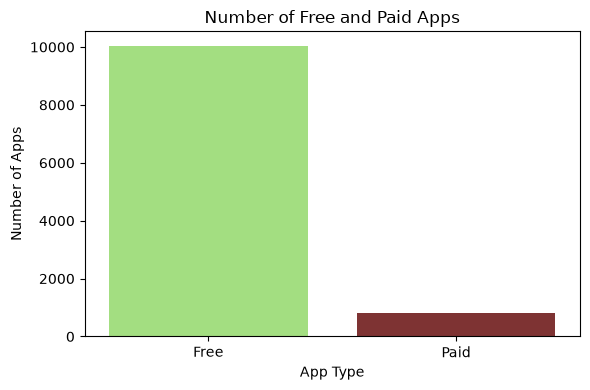

In [10]:
plt.figure(figsize=(6, 4))

sns.countplot(data=data, x="Type", palette=["#9FED72", "#8B2626"])

plt.title("Number of Free and Paid Apps")
plt.xlabel("App Type")
plt.ylabel("Number of Apps")
plt.tight_layout()
plt.show()

### Genres with More Than 200 Apps
- This chart shows the genres with more than 200 apps in the dataset. It helps identify which genres contain a larger number of applications on the Google Play Store.

In [11]:
genre_counts = data["Genres"].value_counts()
high_genre = genre_counts[genre_counts > 200]
high_genre

Genres
Tools                842
Entertainment        623
Education            549
Medical              463
Business             460
Productivity         424
Sports               398
Personalization      392
Communication        387
Lifestyle            381
Finance              366
Action               365
Health & Fitness     341
Photography          335
Social               295
News & Magazines     283
Shopping             260
Travel & Local       257
Dating               234
Books & Reference    231
Arcade               220
Name: count, dtype: int64

C:\Users\TS\AppData\Local\Temp\ipykernel_8372\10686274.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=high_genre.index, y=high_genre.values, palette="mako" ,legend=False)


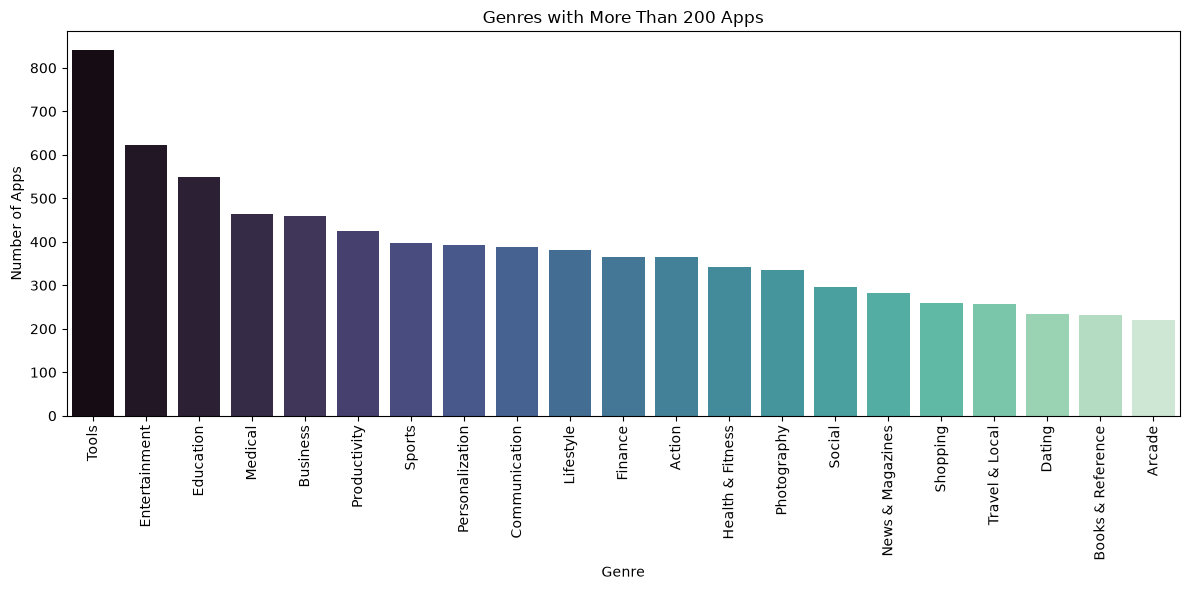

In [12]:
plt.figure(figsize=(12, 6))

sns.barplot(x=high_genre.index, y=high_genre.values, palette="mako" ,legend=False)

plt.xticks(rotation=90)
plt.xlabel("Genre")
plt.ylabel("Number of Apps")
plt.title("Genres with More Than 200 Apps")
plt.tight_layout()
plt.show()

In [13]:
data["Installs"].value_counts()

Installs
1000000       1579
10000000      1252
100000        1169
10000         1054
1000           907
5000000        752
100            719
500000         539
50000          479
5000           477
100000000      409
10             386
500            330
50000000       289
50             205
5               82
500000000       72
1               67
1000000000      58
0               15
Name: count, dtype: int64

### 20 Most Common Install Thresholds
- This chart presents the 20 most common reported install thresholds among the apps. It shows how frequently different installation thresholds appear in the dataset.

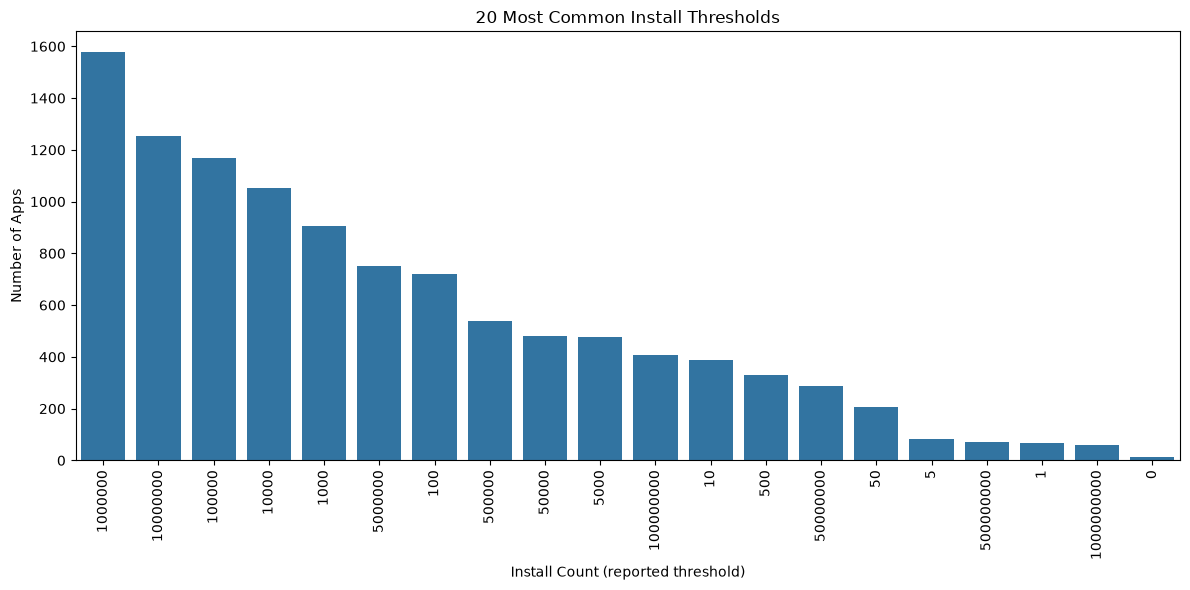

In [14]:
install_counts = data["Installs"].value_counts().head(20)

plt.figure(figsize=(12, 6))

sns.barplot(x=install_counts.index.astype(str), y=install_counts.values)

plt.xticks(rotation=90)
plt.xlabel("Install Count (reported threshold)")
plt.ylabel("Number of Apps")
plt.title("20 Most Common Install Thresholds")
plt.tight_layout()
plt.show()

### Installs vs Reviews
- This scatter plot illustrates the relationship between the reported number of installs and the number of reviews. The data points are widely distributed, indicating substantial variation among apps in both measures. A large number of apps have relatively low values, while some have much higher values.

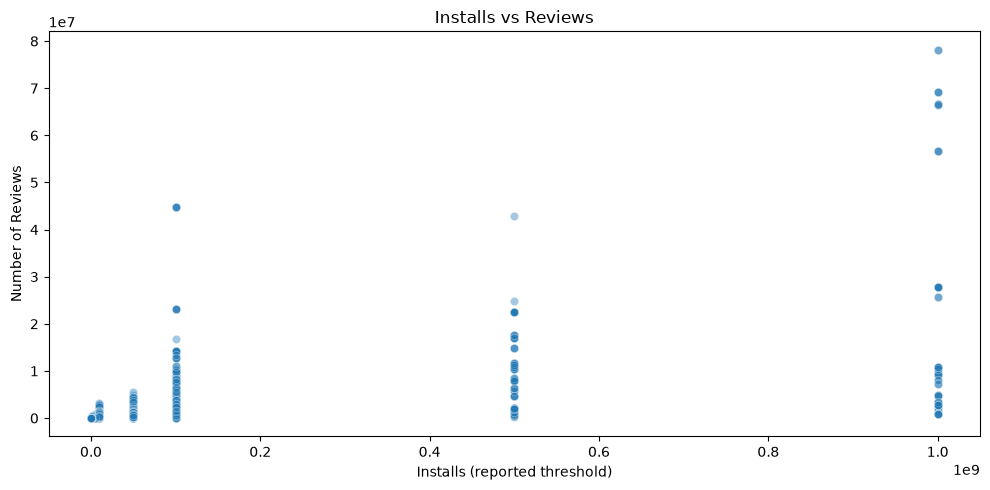

In [15]:
plt.figure(figsize=(10, 5))

sns.scatterplot(data=data, x="Installs", y="Reviews", alpha=0.4)

plt.xlabel("Installs (reported threshold)")
plt.ylabel("Number of Reviews")
plt.title("Installs vs Reviews")
plt.tight_layout()
plt.show()

### Installs vs Reviews — Log Scale
- Since the install and review counts have highly different scales, logarithmic scaling is used to make the distribution of data points easier to examine. This visualization provides a clearer view of apps with both low and high reported values.

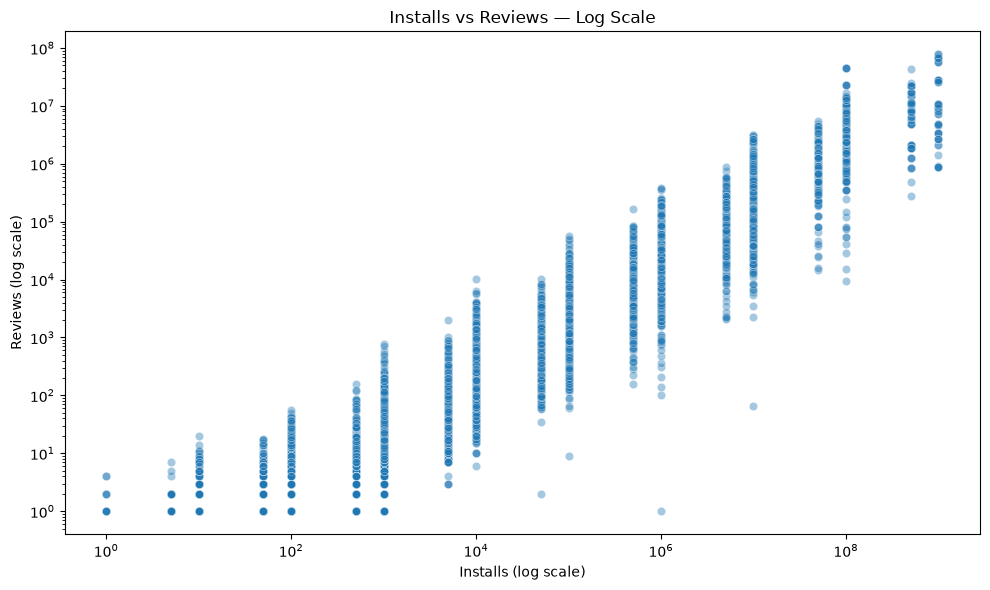

In [16]:
plt.figure(figsize=(10, 6))
reviews_data = data[ (data["Installs"] > 0) & (data["Reviews"] > 0)]
sns.scatterplot(data=reviews_data, x="Installs", y="Reviews", alpha=0.4)

plt.xscale("log")
plt.yscale("log")

plt.xlabel("Installs (log scale)")
plt.ylabel("Reviews (log scale)")
plt.title("Installs vs Reviews — Log Scale")
plt.tight_layout()
plt.show()

### Top 21 Genres by Reported Install Thresholds
- This chart compares the sum of reported install thresholds across the top 21 genres. It provides an overview of the genres with higher combined reported installation thresholds. However, these values represent reported thresholds rather than exact install counts.

In [17]:
data_plot = data.groupby("Genres")["Installs"].sum()
data_plot = data_plot.sort_values(ascending=False).head(21)
data_plot

Genres
Communication              32647276251
Productivity               14176091369
Social                     14069867902
Tools                      11442771915
Arcade                     10727129155
Photography                10088247655
Casual                      9662830740
Action                      9342039190
News & Magazines            7496317760
Travel & Local              6868787146
Video Players & Editors     6207002720
Entertainment               5064214684
Shopping                    3247848785
Sports                      2867174498
Personalization             2325494782
Racing                      2000247320
Strategy                    1974187605
Books & Reference           1921469576
Puzzle                      1668476811
Health & Fitness            1583072512
Business                    1001914865
Name: Installs, dtype: int64

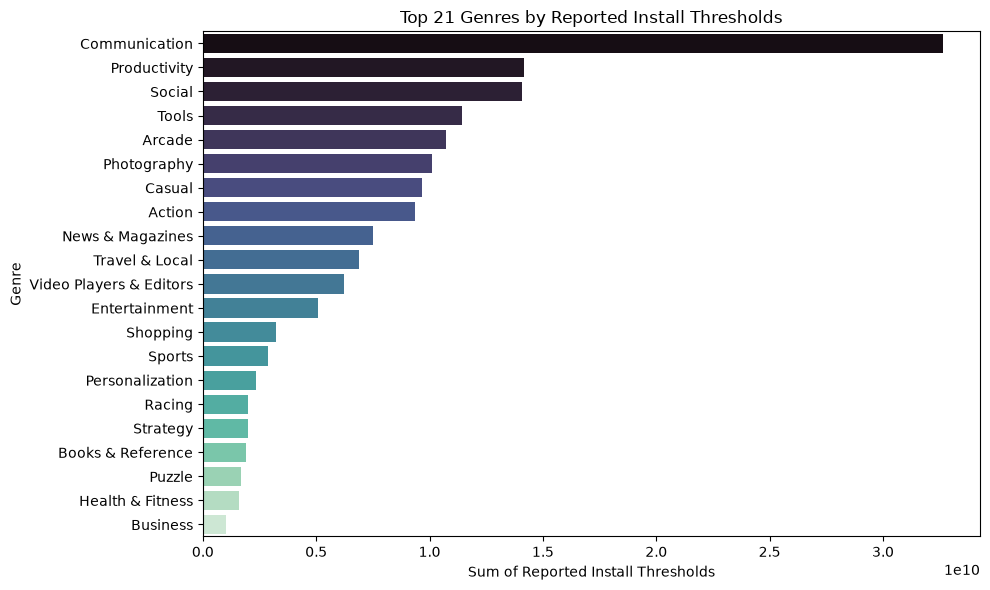

In [18]:
plt.figure(figsize=(10, 6))

sns.barplot(x=data_plot.values, y=data_plot.index ,hue=data_plot.index , palette="mako" ,legend=False)

plt.xlabel("Sum of Reported Install Thresholds")
plt.ylabel("Genre")
plt.title("Top 21 Genres by Reported Install Thresholds")
plt.tight_layout()
plt.show()

### Distribution of App Ratings
- This histogram illustrates the distribution of app ratings in the dataset. It shows how ratings are spread across different score ranges and helps identify the most common rating intervals.

In [19]:
missing_rating = data["Rating"].isna().sum()
missing_percentage = (data["Rating"].isna().mean() * 100)

print("Missing ratings:", missing_rating)
print("Missing percentage:", missing_percentage)

Missing ratings: 1474
Missing percentage: 13.597785977859777


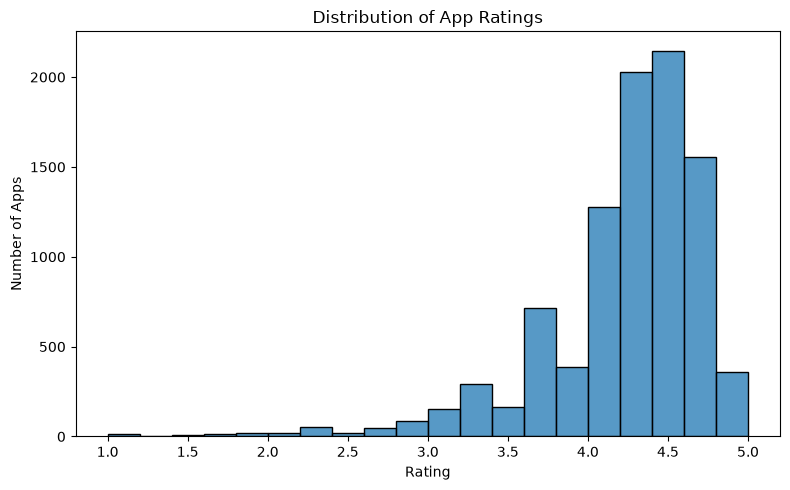

In [20]:
plt.figure(figsize=(8, 5))

sns.histplot(data=data, x="Rating", bins=20)

plt.xlabel("Rating")
plt.ylabel("Number of Apps")
plt.title("Distribution of App Ratings")
plt.tight_layout()
plt.show()

### Installs vs Rating

- This scatter plot explores the relationship between the reported number of installs and app ratings. It helps examine how ratings are distributed among apps with different installation thresholds.

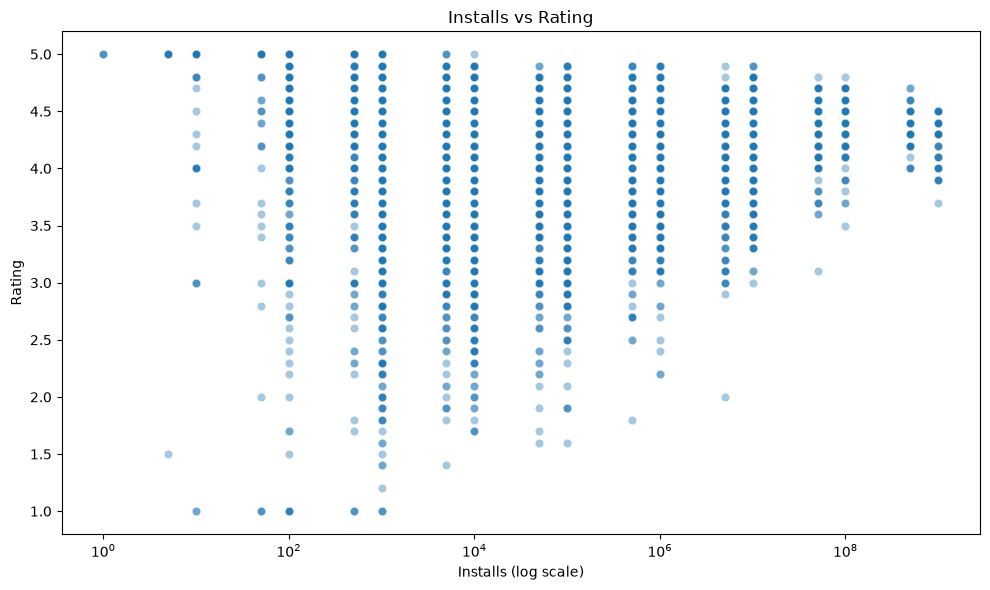

In [21]:
rating_data = data.dropna(subset=["Rating"])
rating_data = rating_data[(rating_data["Installs"] > 0) & (rating_data["Reviews"] > 0)]

plt.figure(figsize=(10, 6))

sns.scatterplot(data=rating_data, x="Installs", y="Rating", alpha=0.4)

plt.xscale("log")
plt.xlabel("Installs (log scale)")
plt.ylabel("Rating")
plt.title("Installs vs Rating")

plt.tight_layout()
plt.show()

# Conclusion
In this project, I explored the Google Play Store dataset using Python and performed several data analysis tasks.

The analysis covered different aspects of the apps, including:

- The distribution of free and paid apps.
- The number of apps across different genres.
- The most common reported install thresholds.
- The relationship between installs and reviews.
- The distribution of app ratings.
- The relationship between installs and ratings.
- The sum of reported install thresholds across different genres.

These visualizations provide an overview of the characteristics of apps available on the Google Play Store and help identify patterns in the dataset.

# Limitations
There are some limitations in this dataset that should be considered when interpreting the results:

- **Missing Ratings:** Some apps do not have rating values, which may affect the analysis of app ratings.
- **Install Thresholds:** The install values are reported as thresholds (such as 1,000+ or 5,000+) rather than exact installation counts.
- **Data Quality:** The dataset contains some inconsistent or incorrectly formatted values that require cleaning before analysis.
- **Interpretation:** The relationships observed in the visualizations do not necessarily indicate causation.